# Unstructured-grid access patterns

How can dynamical.org best structure datasets whose horizontal spatial dimensions don't follow a 2D grid? For example, grids like reduced gaussian (e.g. ECMWF IFS), icosahedral (e.g. DWD ICON), and HEALPix. This notebook explores common usage patterns and open source library interoperability using a draft dataset structure + metadata applied to a real world dataset, DWD's ICON-EU. Our goal is to make the user experience as simple as possible by following existing conventions.

**Proposed convention**
1. Horizontal space is laid out along a single `cell` dimension, with `latitude` and `longitude` coordinates giving each cell's center.
2. When the source grid defines cell polygons (e.g. ICON's triangles), a `mesh/` group holds them following the UGRID convention. Grids without stored polygons (reduced Gaussian, HEALPix) have no `mesh/` group.

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog 'xarray>=2026.2' matplotlib cartopy shapely scipy 'uxarray[viz,geo]>=2026.10.1'

In [2]:
# In staging for feedback, structure may change in breaking ways before promotion to prod.
import os
os.environ.setdefault("DYNAMICAL_STAC_CATALOG_URL", "https://stac-staging.dynamical.org/catalog.json")

import dynamical_catalog

ds = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", chunks=None)
ds

<xarray.Dataset> Size: 967GB
Dimensions:                                             (init_time: 178,
                                                         lead_time: 93,
                                                         cell: 768608)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 132kB ...
  * cell                                                (cell) int32 3MB 0 .....
    latitude                                            (cell) float32 3MB ...
    longitude                                           (cell) float32 3MB ...
    spatial_ref                                         int64 8B ...
Data variables: (12/19)
    cloud_cover_low                                     (init_time, lead_time, cell) float32 51GB ...
    dew_point_temperature_2m                            (init_time, lead_time, cell) float32 51GB ...
    cloud_cover_high                                    (init_time, lead_time, cell) float32 51GB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time, cell) float32 51GB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time, cell) float32 51GB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time, cell) float32 51GB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time, cell) float32 51GB ...
    wind_u_10m                                          (init_time, lead_time, cell) float32 51GB ...
    wind_v_10m                                          (init_time, lead_time, cell) float32 51GB ...
    wind_gust_10m                                       (init_time, lead_time, cell) float32 51GB ...
    snow_water_equivalent_surface                       (init_time, lead_time, cell) float32 51GB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time, cell) float32 51GB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

## 1. Point selection

### 1a. xarray

Quick and simple. Only drawback is distance is in degrees, not meters. In most cases that's equivalent for this purpose.

In [3]:
import xarray as xr

ds = ds.set_xindex(("latitude", "longitude"), xr.indexes.NDPointIndex)
ds.sel(latitude=38, longitude=-9, method="nearest")

<xarray.Dataset> Size: 1MB
Dimensions:                                             (init_time: 178,
                                                         lead_time: 93)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 132kB ...
    cell                                                int32 4B 481735
    spatial_ref                                         int64 8B ...
    latitude                                            float32 4B 38.01
    longitude                                           float32 4B -9.008
Data variables: (12/19)
    cloud_cover_low                                     (init_time, lead_time) float32 66kB ...
    dew_point_temperature_2m                            (init_time, lead_time) float32 66kB ...
    cloud_cover_high                                    (init_time, lead_time) float32 66kB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time) float32 66kB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time) float32 66kB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time) float32 66kB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time) float32 66kB ...
    wind_u_10m                                          (init_time, lead_time) float32 66kB ...
    wind_v_10m                                          (init_time, lead_time) float32 66kB ...
    wind_gust_10m                                       (init_time, lead_time) float32 66kB ...
    snow_water_equivalent_surface                       (init_time, lead_time) float32 66kB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time) float32 66kB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

### 1b. UXarray

Find the face containing the point on the sphere; this requires the mesh.

In [4]:
import uxarray as ux

mesh = dynamical_catalog.open("dwd-icon-eu-forecast-5-day-icosahedral", group="mesh", chunks=None)
uxgrid = ux.open_grid(mesh)
point_faces = uxgrid.get_faces_containing_point((-9, 38), return_counts=False)[0]
ds.isel(cell=point_faces)

<xarray.Dataset> Size: 1MB
Dimensions:                                             (init_time: 178,
                                                         lead_time: 93, cell: 1)
Coordinates:
  * init_time                                           (init_time) datetime64[ns] 1kB ...
    ingested_forecast_length                            (init_time) timedelta64[us] 1kB ...
    expected_forecast_length                            (init_time) timedelta64[us] 1kB ...
  * lead_time                                           (lead_time) timedelta64[us] 744B ...
    valid_time                                          (init_time, lead_time) datetime64[ns] 132kB ...
  * cell                                                (cell) int32 4B 481735
    latitude                                            (cell) float32 4B 38.01
    longitude                                           (cell) float32 4B -9.008
    spatial_ref                                         int64 8B ...
Data variables: (12/19)
    cloud_cover_low                                     (init_time, lead_time, cell) float32 66kB ...
    dew_point_temperature_2m                            (init_time, lead_time, cell) float32 66kB ...
    cloud_cover_high                                    (init_time, lead_time, cell) float32 66kB ...
    downward_diffuse_short_wave_radiation_flux_surface  (init_time, lead_time, cell) float32 66kB ...
    convective_available_potential_energy_atmosphere    (init_time, lead_time, cell) float32 66kB ...
    downward_direct_short_wave_radiation_flux_surface   (init_time, lead_time, cell) float32 66kB ...
    ...                                                  ...
    temperature_2m                                      (init_time, lead_time, cell) float32 66kB ...
    wind_u_10m                                          (init_time, lead_time, cell) float32 66kB ...
    wind_v_10m                                          (init_time, lead_time, cell) float32 66kB ...
    wind_gust_10m                                       (init_time, lead_time, cell) float32 66kB ...
    snow_water_equivalent_surface                       (init_time, lead_time, cell) float32 66kB ...
    total_cloud_cover_atmosphere                        (init_time, lead_time, cell) float32 66kB ...
Attributes:
    dataset_id:           dwd-icon-eu-forecast-5-day-icosahedral
    dataset_version:      0.1.0
    name:                 DWD ICON-EU forecast, 5 day, icosahedral
    description:          High-resolution weather forecasts for Europe from t...
    attribution:          DWD ICON-EU data processed by dynamical.org.
    license:              CC-BY-4.0
    spatial_domain:       Europe
    spatial_resolution:   6.5 km
    time_domain:          Forecasts initialized 2026-10-07 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-120 hours (0-5 days) ahead
    forecast_resolution:  Forecast step 0-78 hours: hourly, 81-120 hours: 3 h...

## 2. Select bounding box

In [5]:
field = ds["temperature_2m"].sel(init_time="2026-11-10T00", lead_time="12h").load()

### 2a. xarray

Using xarray only, select cells whose centers fall inside the box; boundary cells can extend outside it.

In [6]:
box = field.isel(cell=(
    (field.longitude >= -10) & (field.longitude <= -6)
    & (field.latitude >= 37) & (field.latitude <= 42.5)
))
box

<xarray.DataArray 'temperature_2m' (cell: 4718)> Size: 19kB
array([20.375 , 20.25  , 20.375 , ..., 12.625 , 13.5625, 13.1875],
      shape=(4718,), dtype=float32)
Coordinates:
  * cell                      (cell) int32 19kB 411173 411174 ... 512750 512751
    latitude                  (cell) float32 19kB 37.53 37.62 ... 42.04 42.06
    longitude                 (cell) float32 19kB -9.981 -9.94 ... -7.478 -7.543
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 2b. UXarray

Select faces wholly inside the box.

In [7]:
uxfield = ux.UxDataArray.from_xarray(field, uxgrid)
uxfield.subset.bounding_box((-10, -6), (37, 42.5))

<xarray.UxDataArray 'temperature_2m' (n_face: 4517)> Size: 18kB
array([20.25  , 20.    , 19.875 , ..., 12.625 , 13.5625, 13.1875],
      shape=(4517,), dtype=float32)
Coordinates:
    cell                      (n_face) int32 18kB 411174 411185 ... 512751
    latitude                  (n_face) float32 18kB 37.62 37.7 ... 42.04 42.06
    longitude                 (n_face) float32 18kB -9.94 -9.899 ... -7.543
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Dimensions without coordinates: n_face
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

## 3. Map plotting

### 3a. Matplotlib

Tripcolor joins neighboring cell centers into triangles colored by the mean of their three cells, rather than giving each native cell its own color.

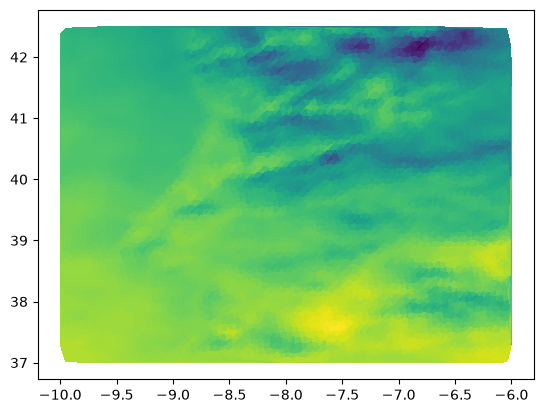

In [8]:
import matplotlib.pyplot as plt

plt.tripcolor(box.longitude, box.latitude, box);

### 3b. UXarray

Draw native polygons for the same center-selected cells with UXarray’s built-in Matplotlib backend.

:Image   [x,y]   (x_y temperature_2m)
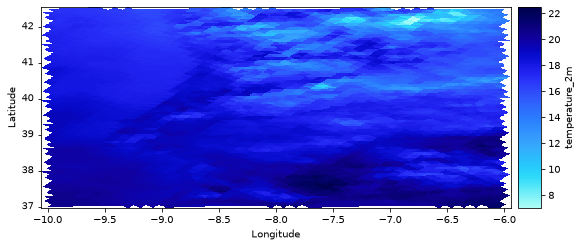

In [9]:
uxfield.isel(n_face=box.cell.values).plot(backend="matplotlib")

## 4. Arbitrary geometry means

### 4a. Shapely and xarray

Average cells whose centers lie in a coarse polygon around mainland Portugal; cells are not clipped at its edges.

In [10]:
import shapely

mainland = shapely.Polygon([
    (-9.5, 38.7), (-8.9, 41.9), (-6.2, 41.9), (-7.5, 39.7), (-7.4, 37), (-8.9, 37),
])
polygon_cells = shapely.contains_xy(mainland, field.longitude.values, field.latitude.values)
field.isel(cell=polygon_cells).mean("cell")

<xarray.DataArray 'temperature_2m' ()> Size: 4B
array(17.983597, dtype=float32)
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 4b. UXarray

Weight the same center-selected cells by spherical face area; the polygon mask still comes from Shapely.

In [11]:
uxpolygon = uxfield.isel(n_face=polygon_cells)
uxpolygon.weighted(uxpolygon.uxgrid.face_areas).mean("n_face")

<xarray.UxDataArray 'temperature_2m' ()> Size: 8B
array(17.98047205)
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

### 4c. Shapely intersection areas

Clip each native cell to the same polygon and weight by its intersection area, scaled by cos(latitude) to approximate area on the sphere. Here the mean is 0.006 °C lower than 4a and 0.003 °C lower than 4b.

In [12]:
import numpy as np

nodes = mesh.face_node_connectivity.values
vertices = np.stack((mesh.node_longitude.values[nodes], mesh.node_latitude.values[nodes]), axis=-1)
overlap = shapely.area(shapely.intersection(shapely.polygons(vertices), mainland))
field.weighted(overlap * np.cos(np.deg2rad(field.latitude))).mean("cell")

<xarray.DataArray 'temperature_2m' ()> Size: 8B
array(17.97722132)
Coordinates:
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-11-10
    lead_time                 timedelta64[us] 8B 12:00:00
    expected_forecast_length  timedelta64[us] 8B 5 days
    spatial_ref               int64 8B 0
    valid_time                datetime64[ns] 8B 2026-11-10T12:00:00
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant
    mesh:           /mesh/mesh
    location:       face

## 5. Regridding (remapping)

### 5a. xarray

Quick nearest-neighbor remapping; assign the target coordinates because selection returns source centers.

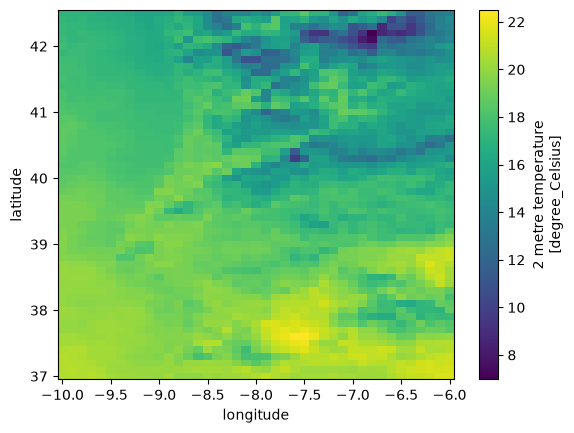

In [13]:
target = xr.Dataset(coords={
    "latitude": np.arange(37, 42.51, 0.1),
    "longitude": np.arange(-10, -5.99, 0.1),
})
regular = field.sel(latitude=target.latitude, longitude=target.longitude, method="nearest")
regular = regular.assign_coords(target.coords)
regular.reset_coords(drop=True).plot();

### 5b. UXarray

Interpolate from four nearby centers using spherical distances; restoring the target dimensions takes an explicit reshape.

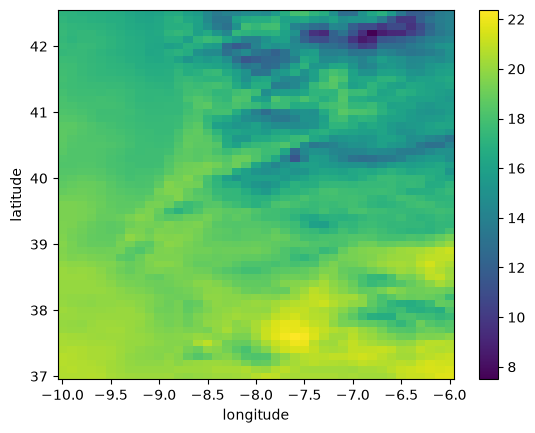

In [14]:
target_mesh = ux.Grid.from_structured(lon=target.longitude.values, lat=target.latitude.values)
interpolated = uxfield.remap.inverse_distance_weighted(target_mesh, k=4)
xr.DataArray(interpolated.values.reshape(regular.shape), coords=target.coords, dims=("latitude", "longitude")).plot();